# Lead Scoring Case Study – X Education

**Submitted by:** Vishnuvardhan Reddy Janagam &nbsp;|&nbsp; **Program:** IIIT Bangalore – Data Science with Generative AI

---

## Business problem
X Education sells online courses to working professionals. Many people land on the website, but only a small share of the leads the sales team calls actually buy a course. The company wants a **lead score (0–100)** so that the sales team can spend its time on the *hot leads* (high score) and stop wasting calls on cold ones. The CEO's target is a lead conversion rate of about **80%** among the leads that get worked.

## My approach
| Step | What I do |
|---|---|
| 1 | Understand the data and clean it (the `Select` levels, missing values, outliers, rare levels) |
| 2 | EDA – see which variables separate converted from non-converted leads |
| 3 | Prepare data – dummy variables, 70:30 train-test split, scaling |
| 4 | Build a logistic regression: RFE for the first cut, then remove variables by p-value and VIF |
| 5 | Evaluate on train, choose the probability cut-off, then confirm on the test set |
| 6 | Convert probabilities to a lead score and answer the four business questions |
| 7 | Compare with a few other models (tree, random forest, model without sales-assigned fields) |

**Assumption I am making (stated upfront):** the `Tags` column is filled in by the sales team while they nurture a lead. So my final model is a *nurturing-stage* model. I also build a model without `Tags`, to show what happens if we must score a brand-new lead before any call.

## 1. Setup

In [129]:
# core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# modelling libraries
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from scipy.stats import norm

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 150)
sns.set_style('whitegrid')
RANDOM_STATE = 100

## 2. Data understanding

In [130]:
leads = pd.read_csv('Leads.csv')     # Leads.csv sits in the same folder as this notebook
print('Rows, columns:', leads.shape)
leads.head()

Rows, columns: (9240, 37)


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,What matters most to you in choosing a course,Search,Magazine,Newspaper Article,X Education Forums,Newspaper,Digital Advertisement,Through Recommendations,Receive More Updates About Our Courses,Tags,Lead Quality,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,Page Visited on Website,NaN,Select,Select,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Interested in other courses,Low in Relevance,No,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,Email Opened,India,Select,Select,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Ringing,NaN,No,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,Email Opened,India,Business Administration,Select,Student,Better Career Prospects,No,No,No,No,No,No,No,No,Will revert after reading the email,Might be,No,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,Unreachable,India,Media and Advertising,Word Of Mouth,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Ringing,Not Sure,No,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,Converted to Lead,India,Select,Other,Unemployed,Better Career Prospects,No,No,No,No,No,No,No,No,Will revert after reading the email,Might be,No,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


In [131]:
# data types and non-null counts
leads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   object 
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   object 
 3   Lead Source                                    9204 non-null   object 
 4   Do Not Email                                   9240 non-null   object 
 5   Do Not Call                                    9240 non-null   object 
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 

In [132]:
# summary of the numeric columns
leads.describe().round(2)

,Lead Number,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Asymmetrique Activity Score,Asymmetrique Profile Score
count,9240.00,9240.00,9103.00,9240.00,9103.00,5022.00,5022.00
mean,617188.44,0.39,3.45,487.70,2.36,14.31,16.34
std,23406.00,0.49,4.85,548.02,2.16,1.39,1.81
min,579533.00,0.00,0.00,0.00,0.00,7.00,11.00
25%,596484.50,0.00,1.00,12.00,1.00,14.00,15.00
50%,615479.00,0.00,3.00,248.00,2.00,14.00,16.00
75%,637387.25,1.00,5.00,936.00,3.00,15.00,18.00
max,660737.00,1.00,251.00,2272.00,55.00,18.00,20.00


In [133]:
# duplicates - each row should be one unique lead
print('Duplicate rows        :', leads.duplicated().sum())
print('Duplicate Prospect ID :', leads['Prospect ID'].duplicated().sum())
print('Duplicate Lead Number :', leads['Lead Number'].duplicated().sum())

# target variable
print('Overall conversion rate:', round(leads['Converted'].mean() * 100, 1), '%')

Duplicate rows        : 0
Duplicate Prospect ID : 0
Duplicate Lead Number : 0
Overall conversion rate: 38.5 %


No duplicates, so nothing to remove there. The overall conversion rate in this file is **38.5%** (the brief says "around 30%"; I use what the data shows).

## 3. Data cleaning

### 3.1 The `Select` level
Several dropdown columns contain the level `Select`. That is just the default placeholder in the form – the customer never chose anything – so it carries the same information as a null value. I convert it to `NaN`.

In [134]:
# how many 'Select' values are hiding in each column?
select_counts = (leads == 'Select').sum()
select_counts[select_counts > 0]

,0
Specialization,1942
How did you hear about X Education,5043
Lead Profile,4146
City,2249


In [135]:
leads = leads.replace('Select', np.nan)

### 3.2 Missing values

In [136]:
missing_pct = (leads.isnull().mean() * 100).round(2).sort_values(ascending=False)
missing_pct[missing_pct > 0]

,0
How did you hear about X Education,78.46
Lead Profile,74.19
Lead Quality,51.59
Asymmetrique Profile Index,45.65
Asymmetrique Activity Index,45.65
Asymmetrique Activity Score,45.65
Asymmetrique Profile Score,45.65
City,39.71
Specialization,36.58
Tags,36.29


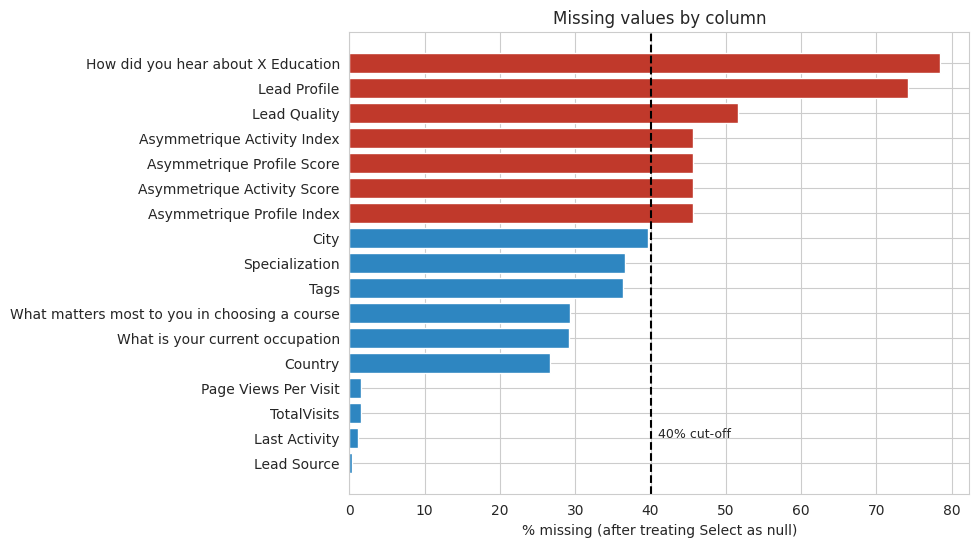

In [137]:
# visualise missing % and the 40% rule I will use for dropping columns
plt.figure(figsize=(8, 6))
to_plot = missing_pct[missing_pct > 0].sort_values()
plt.barh(to_plot.index, to_plot.values, color=['#c0392b' if v > 40 else '#2e86c1' for v in to_plot.values])
plt.axvline(40, color='black', linestyle='--')
plt.text(41, 1, '40% cut-off', fontsize=9)
plt.xlabel('% missing (after treating Select as null)')
plt.title('Missing values by column')
plt.show()

Columns with more than **40% missing** cannot be imputed reliably (I would be inventing most of the column), so I drop them. `Lead Quality` is in this group as well – it is the sales employee's gut-feel rating, so it is subjective and not available for half of the leads anyway.

In [138]:
high_missing = missing_pct[missing_pct > 40].index.tolist()
print('Dropping', len(high_missing), 'columns:')
print(high_missing)
leads = leads.drop(columns=high_missing)

Dropping 7 columns:
['How did you hear about X Education', 'Lead Profile', 'Lead Quality', 'Asymmetrique Profile Index', 'Asymmetrique Activity Index', 'Asymmetrique Activity Score', 'Asymmetrique Profile Score']


### 3.3 Columns with almost no variation
If one level makes up more than 95% of a column, the column cannot help separate converted from non-converted leads (and it can only add noise). Let me find them.

In [139]:
# share of the most common level in every text column (NaN ignored)
dominant_share = {}
for col in leads.select_dtypes(exclude='number').columns:
    dominant_share[col] = leads[col].value_counts(normalize=True).iloc[0]
dominant_share = pd.Series(dominant_share).sort_values(ascending=False)
dominant_share.head(16).round(4)

,0
Magazine,1.0000
Receive More Updates About Our Courses,1.0000
Update me on Supply Chain Content,1.0000
Get updates on DM Content,1.0000
I agree to pay the amount through cheque,1.0000
X Education Forums,0.9999
Newspaper,0.9999
Newspaper Article,0.9998
Do Not Call,0.9998
Digital Advertisement,0.9996


In [140]:
skewed_cols = dominant_share[dominant_share > 0.95].index.tolist()
print('Dropping', len(skewed_cols), 'columns:', skewed_cols)
leads = leads.drop(columns=skewed_cols)

# keep the IDs aside - needed later to attach the lead score to each lead
lead_ids = leads[['Prospect ID', 'Lead Number']].copy()
leads = leads.drop(columns=['Prospect ID', 'Lead Number'])
print('Columns left:', leads.shape[1])

Dropping 14 columns: ['Magazine', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'I agree to pay the amount through cheque', 'X Education Forums', 'Newspaper', 'Newspaper Article', 'Do Not Call', 'Digital Advertisement', 'What matters most to you in choosing a course', 'Through Recommendations', 'Search', 'Country']
Columns left: 14


### 3.4 Is "missing" itself informative?
Before I fill the remaining gaps, let me check whether leads with a missing value behave differently. If they do, I should keep them as their own group instead of guessing a value.

In [141]:
rows = []
for col in ['Tags', 'What is your current occupation', 'Specialization', 'City']:
    is_missing = leads[col].isnull()
    rows.append([col, is_missing.sum(),
                 round(leads.loc[is_missing, 'Converted'].mean() * 100, 1),
                 round(leads.loc[~is_missing, 'Converted'].mean() * 100, 1)])
pd.DataFrame(rows, columns=['Column', 'Missing rows', 'Conversion % when missing', 'Conversion % when filled'])

,Column,Missing rows,Conversion % when missing,Conversion % when filled
0,Tags,3353,24.9,46.3
1,What is your current occupation,2690,13.8,48.7
2,Specialization,3380,28.7,44.2
3,City,3669,34.3,41.4


Leads with a missing occupation convert at 13.8% against 48.7% for the rest, and missing `Tags` (24.9% vs 46.3%) behaves differently too. So **filling with the most common value (mode) would be wrong** – it would hide a real pattern. I will label them `Not Specified` and let the model decide.

### 3.5 Tidy the text columns and treat categorical missing values

In [142]:
binary_cols = ['Do Not Email', 'A free copy of Mastering The Interview']
cat_cols = [c for c in leads.select_dtypes(exclude='number').columns if c not in binary_cols]
print(cat_cols)

# 1) remove stray spaces (e.g. 'Interested  in full time MBA' has a double space)
for col in cat_cols:
    leads[col] = leads[col].str.strip().str.replace(r'\s+', ' ', regex=True)

# 2) same source written two ways
leads['Lead Source'] = leads['Lead Source'].replace({'google': 'Google'})

# 3) missing categorical values become their own level
for col in cat_cols:
    leads[col] = leads[col].fillna('Not Specified')

['Lead Origin', 'Lead Source', 'Last Activity', 'Specialization', 'What is your current occupation', 'Tags', 'City', 'Last Notable Activity']


### 3.6 Rare levels
Many columns have levels with just a handful of leads (for example `Lead Source` has 21 levels, some with one row). A level like that would create a dummy column that is almost always 0, which makes the model unstable. I group every level below **1%** of the data into `Others`.

In [143]:
def group_rare(series, min_share=0.01):
    """Replace levels that are less than min_share of the data with 'Others'."""
    share = series.value_counts(normalize=True)
    rare_levels = share[share < min_share].index.tolist()
    return series.replace(rare_levels, 'Others')

for col in cat_cols:
    before = leads[col].nunique()
    leads[col] = group_rare(leads[col])
    print(f'{col:45s} {before:2d} levels -> {leads[col].nunique():2d}')

Lead Origin                                    5 levels ->  4
Lead Source                                   21 levels ->  8
Last Activity                                 18 levels -> 11
Specialization                                19 levels -> 17
What is your current occupation                7 levels ->  5
Tags                                          27 levels -> 13
City                                           7 levels ->  7
Last Notable Activity                         16 levels ->  7


### 3.7 Yes / No columns

In [144]:
for col in binary_cols:
    leads[col] = leads[col].map({'Yes': 1, 'No': 0})
leads[binary_cols].mean().round(3)

,0
Do Not Email,0.079
A free copy of Mastering The Interview,0.313


### 3.8 Numeric columns – missing values and outliers
`TotalVisits` and `Page Views Per Visit` have 137 missing rows (1.5%). Both are right-skewed, so I use the **median** (the mean would be pulled up by the outliers). I keep these rows rather than delete them because every lead should receive a score.

In [145]:
num_cols = ['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']
for col in ['TotalVisits', 'Page Views Per Visit']:
    leads[col] = leads[col].fillna(leads[col].median())
leads[num_cols].isnull().sum()

,0
TotalVisits,0
Total Time Spent on Website,0
Page Views Per Visit,0


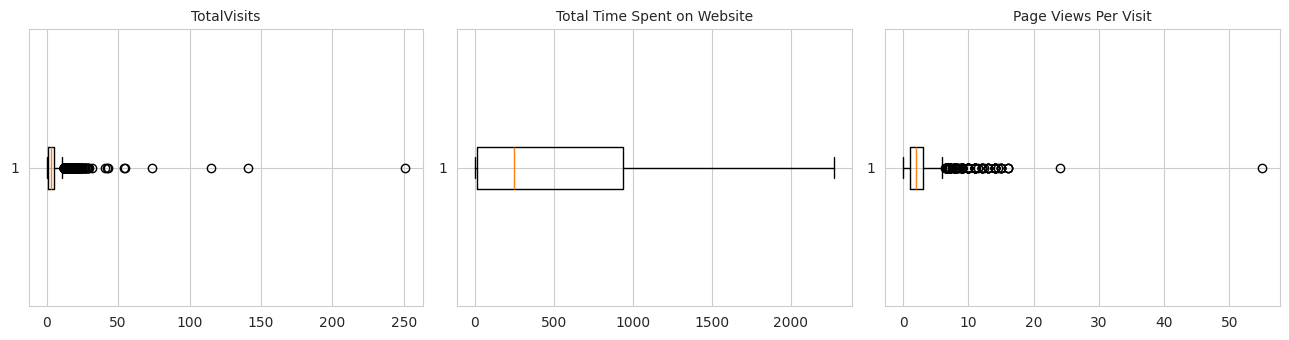

,TotalVisits,Total Time Spent on Website,Page Views Per Visit
count,9240.0,9240.0,9240.0
mean,3.4,487.7,2.4
std,4.8,548.0,2.1
min,0.0,0.0,0.0
50%,3.0,248.0,2.0
90%,7.0,1380.0,5.0
95%,10.0,1562.0,6.0
99%,17.0,1840.6,9.0
max,251.0,2272.0,55.0


In [146]:
# outliers - boxplots
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, num_cols):
    ax.boxplot(leads[col], vert=False)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

# how extreme are the tails?
leads[num_cols].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1)

`TotalVisits` goes up to 251 and `Page Views Per Visit` up to 55, while 99% of leads are far below that. These few extreme values would dominate a scaled model, so I **cap them at the 99th percentile** (winsorising) instead of deleting the rows. `Total Time Spent` has a long tail too, but it is genuine engagement, not an error, so I leave it.

In [147]:
for col in ['TotalVisits', 'Page Views Per Visit']:
    cap = leads[col].quantile(0.99)
    leads[col] = leads[col].clip(upper=cap)
    print(f'{col}: capped at {cap:.1f}')

TotalVisits: capped at 17.0
Page Views Per Visit: capped at 9.0


### 3.9 A new metric – average time per visit
Total time alone does not say *how engaged* a visitor is: 10 minutes over 1 visit is a different behaviour from 10 minutes over 10 visits. I create **`Avg Time Per Visit`** = total time / total visits and test it in the EDA and the model.

In [148]:
leads['Avg Time Per Visit'] = leads['Total Time Spent on Website'] / leads['TotalVisits']
leads['Avg Time Per Visit'] = leads['Avg Time Per Visit'].replace([np.inf, -np.inf], np.nan).fillna(0)   # zero visits -> 0
leads['Avg Time Per Visit'] = leads['Avg Time Per Visit'].clip(upper=leads['Avg Time Per Visit'].quantile(0.99))
num_cols.append('Avg Time Per Visit')
leads['Avg Time Per Visit'].describe().round(1)

,Avg Time Per Visit
count,9240.0
mean,152.8
std,202.7
min,0.0
25%,3.0
50%,68.0
75%,218.6
max,922.6


### 3.10 Final quality check

In [149]:
print('Missing values left :', leads.isnull().sum().sum())
print('Rows, columns       :', leads.shape)
leads.head()

Missing values left : 0
Rows, columns       : (9240, 15)


,Lead Origin,Lead Source,Do Not Email,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Last Activity,Specialization,What is your current occupation,Tags,City,A free copy of Mastering The Interview,Last Notable Activity,Avg Time Per Visit
0,API,Olark Chat,0,0,0.0,0,0.0,Page Visited on Website,Not Specified,Unemployed,Interested in other courses,Not Specified,0,Modified,0.0
1,API,Organic Search,0,0,5.0,674,2.5,Email Opened,Not Specified,Unemployed,Ringing,Not Specified,0,Email Opened,134.8
2,Landing Page Submission,Direct Traffic,0,1,2.0,1532,2.0,Email Opened,Business Administration,Student,Will revert after reading the email,Mumbai,1,Email Opened,766.0
3,Landing Page Submission,Direct Traffic,0,0,1.0,305,1.0,Unreachable,Media and Advertising,Unemployed,Ringing,Mumbai,0,Modified,305.0
4,Landing Page Submission,Google,0,1,2.0,1428,1.0,Converted to Lead,Not Specified,Unemployed,Will revert after reading the email,Mumbai,0,Modified,714.0


## 4. Exploratory data analysis
### 4.1 Target variable

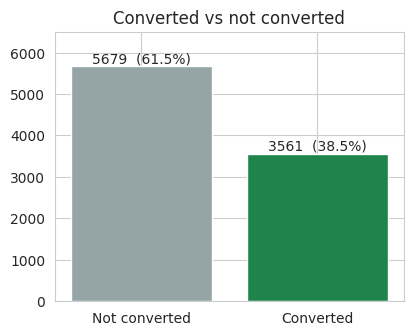

In [150]:
overall_rate = leads['Converted'].mean()
counts = leads['Converted'].value_counts().sort_index()

plt.figure(figsize=(4.5, 3.5))
plt.bar(['Not converted', 'Converted'], counts.values, color=['#95a5a6', '#1e8449'])
for i, v in enumerate(counts.values):
    plt.text(i, v + 80, f'{v}  ({v / len(leads) * 100:.1f}%)', ha='center')
plt.title('Converted vs not converted')
plt.ylim(0, 6500)
plt.show()

The classes are reasonably balanced (61 : 39), so I do not need any resampling.

### 4.2 Numeric variables vs conversion

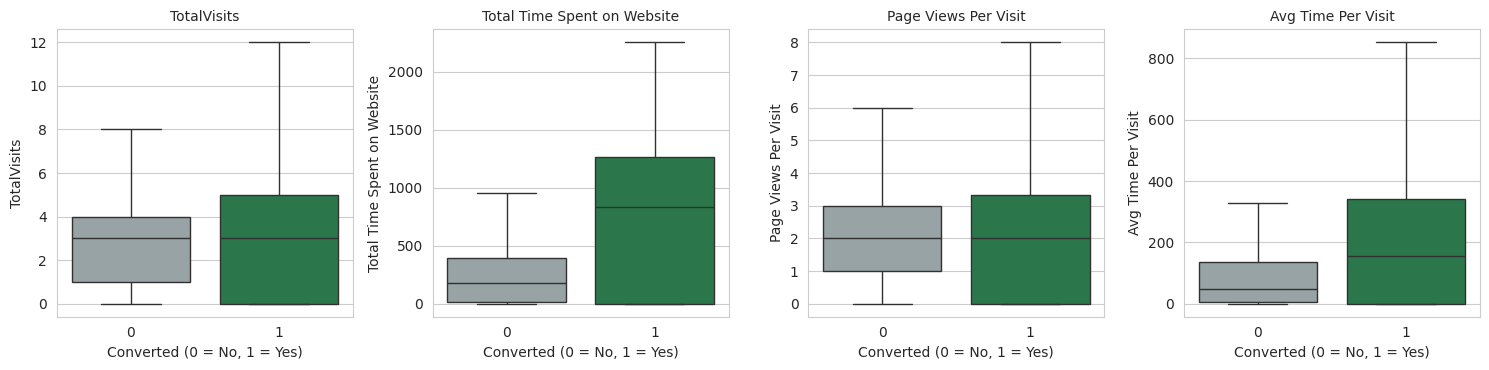

In [151]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x='Converted', y=col, data=leads, ax=ax, showfliers=False, palette=['#95a5a6', '#1e8449'])
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Converted (0 = No, 1 = Yes)')
plt.tight_layout()
plt.show()

In [152]:
# average of each numeric variable for the two groups
leads.groupby('Converted')[num_cols].mean().round(2)

,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Avg Time Per Visit
Converted,,,,
0,3.22,330.40,2.34,113.73
1,3.51,738.55,2.32,215.00


**Insight:** converted leads spend far more time on the website (about 2.2x: 739 vs 330 on average) and also spend more time per visit. Number of visits and pages per visit barely differ between the two groups.

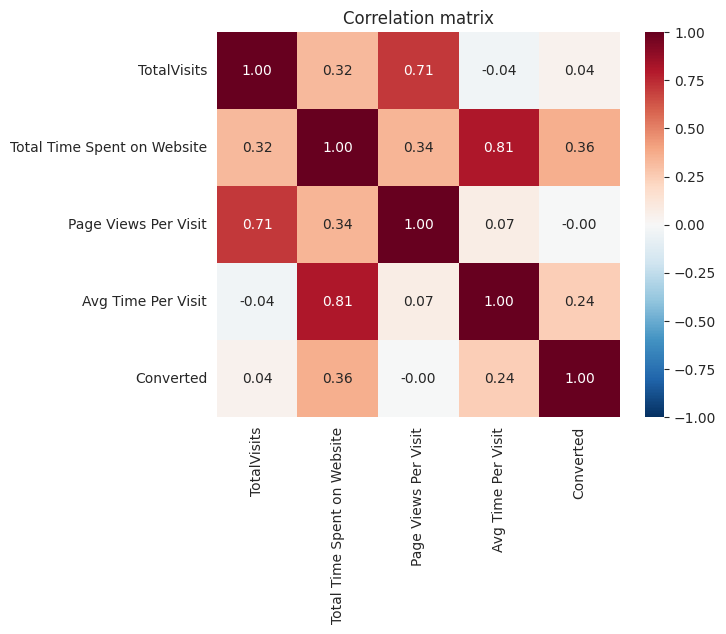

In [153]:
# correlation between the numeric variables and the target
plt.figure(figsize=(6.5, 5))
sns.heatmap(leads[num_cols + ['Converted']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()

`Total Time Spent` is the only numeric variable with a clear link to `Converted` (0.36). `Avg Time Per Visit` is correlated with it, so I expect a multicollinearity issue later; the VIF check will handle that.

### 4.3 Categorical variables vs conversion rate

In [154]:
def plot_conversion_rate(col, ax):
    """Horizontal bar chart: conversion rate of each level, with the number of leads in brackets."""
    summary = leads.groupby(col)['Converted'].agg(['mean', 'count']).sort_values('mean')
    ax.barh(summary.index, summary['mean'] * 100, color='#2e86c1')
    for i, (rate, n) in enumerate(zip(summary['mean'], summary['count'])):
        ax.text(rate * 100 + 1, i, f'{rate * 100:.0f}%  (n={n})', va='center', fontsize=8)
    ax.axvline(overall_rate * 100, color='red', linestyle='--', linewidth=1)
    ax.set_xlim(0, 125)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Conversion rate (%)   |   red line = overall average')

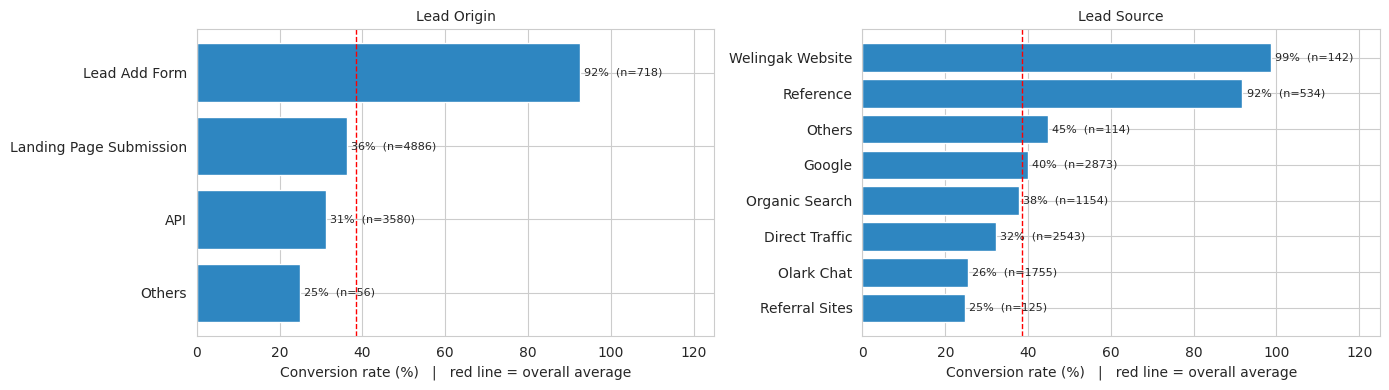

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_conversion_rate('Lead Origin', axes[0])
plot_conversion_rate('Lead Source', axes[1])
plt.tight_layout()
plt.show()

**Insight:** `Lead Add Form` leads convert at ~92% and the sources `Welingak Website` and `Reference` at 92–99%, against ~31–40% for Google / Direct Traffic. Leads that come through a form or referral have already shown intent. `Olark Chat` (26%) and `Referral Sites` (25%) are the weakest sources.

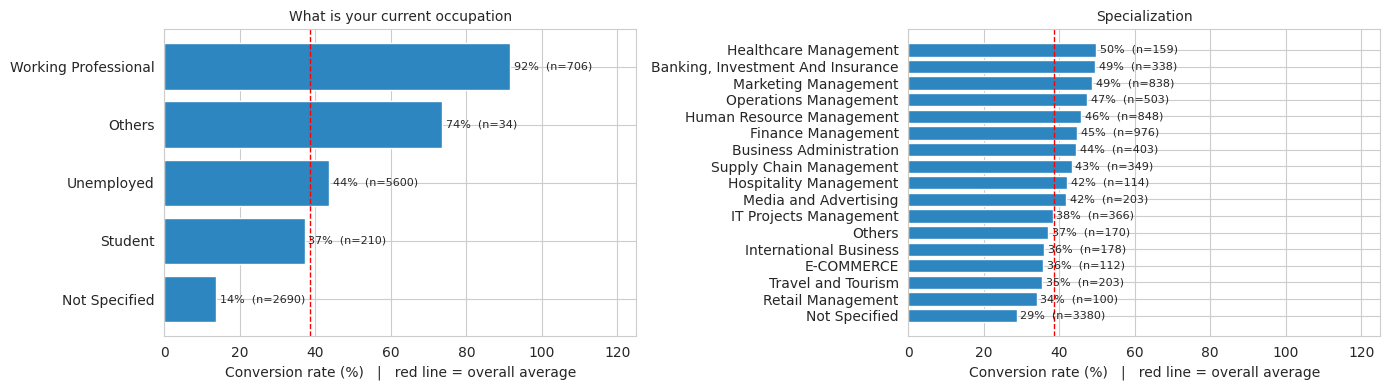

In [156]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_conversion_rate('What is your current occupation', axes[0])
plot_conversion_rate('Specialization', axes[1])
plt.tight_layout()
plt.show()

**Insight:** working professionals convert at ~92% versus 44% for the unemployed. Specialization hardly matters (every named specialization sits between 34% and 50%), except that leads that did not tell us their specialization convert less (29%).

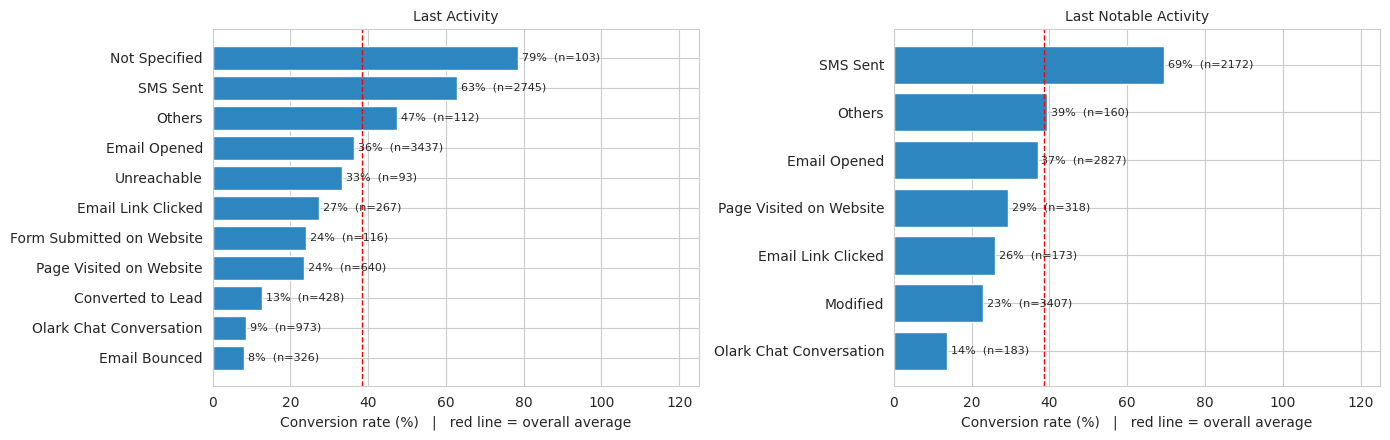

In [157]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_conversion_rate('Last Activity', axes[0])
plot_conversion_rate('Last Notable Activity', axes[1])
plt.tight_layout()
plt.show()

**Insight:** leads whose last activity was an SMS being sent convert at 63–69% – almost double the average. (The 103 leads with no recorded last activity convert at 79%, but that group is tiny.) Olark chat conversations (9%) and bounced emails (8%) are the weakest.

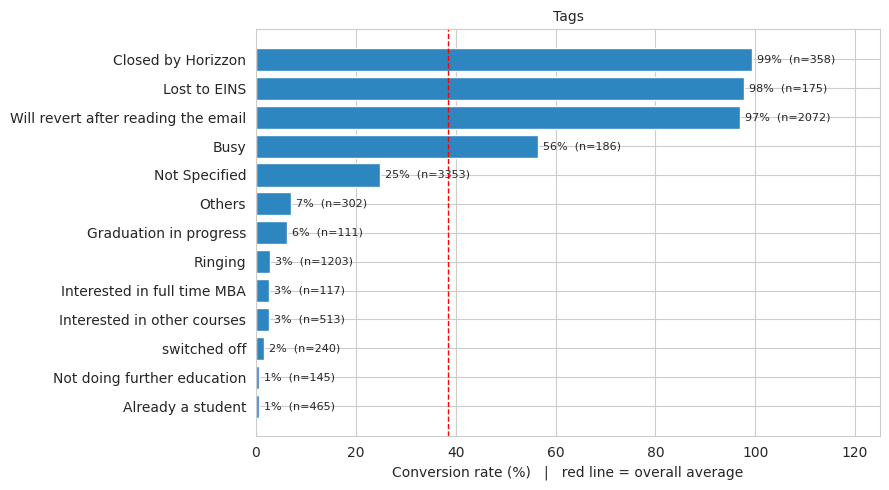

In [158]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_conversion_rate('Tags', ax)
plt.tight_layout()
plt.show()

**Insight:** `Tags` separates the classes very strongly – "Will revert after reading the email", "Closed by Horizzon" and "Lost to EINS" convert at 97–99%, while "Ringing", "switched off", "Already a student" are below 3%. This is a status the sales team records during follow-up, which is why I flagged it as an assumption at the top.

In [159]:
# the two yes/no columns
leads.groupby('Do Not Email')['Converted'].agg(['mean', 'count']).round(3)

,mean,count
Do Not Email,,
0,0.405,8506
1,0.161,734


In [160]:
leads.groupby('A free copy of Mastering The Interview')['Converted'].agg(['mean', 'count']).round(3)

,mean,count
A free copy of Mastering The Interview,,
0,0.398,6352
1,0.357,2888


Leads with `Do Not Email = Yes` convert much less (16% vs 41%). The free interview book makes no real difference.

### 4.4 EDA summary
* Time on website, lead origin/source (forms & referrals), occupation, last activity and tags are the strongest signals.
* City, specialization and the yes/no advertising flags carry little information.
* Missing values are informative, so they are kept as their own level.

## 5. Data preparation for modelling
### 5.1 Dummy variables
For every categorical column I create one 0/1 column per level and **drop one level as the reference**. I use `Not Specified` as the reference where it exists (so every coefficient reads as "compared to a lead with no information"), otherwise the most frequent level.

In [161]:
dummy_frames = []
for col in cat_cols:
    levels = leads[col].unique()
    baseline = 'Not Specified' if 'Not Specified' in levels else leads[col].mode()[0]
    dummies = pd.get_dummies(leads[col], prefix=col, dtype=int)
    dummies = dummies.drop(columns=f'{col}_{baseline}')
    dummy_frames.append(dummies)
    print(f'{col:45s} reference level = {baseline}')

model_data = pd.concat([leads.drop(columns=cat_cols)] + dummy_frames, axis=1)
print('\nModelling data shape:', model_data.shape)

Lead Origin                                   reference level = Landing Page Submission
Lead Source                                   reference level = Google
Last Activity                                 reference level = Not Specified
Specialization                                reference level = Not Specified
What is your current occupation               reference level = Not Specified
Tags                                          reference level = Not Specified
City                                          reference level = Not Specified
Last Notable Activity                         reference level = Modified

Modelling data shape: (9240, 71)


### 5.2 Train-test split (70:30)

In [162]:
X = model_data.drop(columns='Converted')
y = model_data['Converted']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Conversion rate  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

Train: (6468, 70) | Test: (2772, 70)
Conversion rate  train: 0.385  test: 0.385


### 5.3 Scaling
The numeric columns are on very different scales (time is in hundreds, page views in single digits). I standardise them so the coefficients are comparable. The scaler is **fit on the train set only** and then applied to the test set, so nothing from the test data leaks into training.

In [163]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
X_train[num_cols].describe().round(2).loc[['mean', 'std']]

,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Avg Time Per Visit
mean,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


## 6. Model building
I will use logistic regression because the target is binary and, more importantly, the company needs to **explain** why a lead is hot. Coefficients are easy to read as changes in odds.

### 6.1 Helper functions
I need three small tools that I will reuse several times:
* `fit_logit` – fits the logistic regression and returns the coefficient table with standard errors and **p-values** (I write it out with the Newton/IRLS method, which gives the same numbers as a GLM Binomial in statsmodels).
* `vif_table` – variance inflation factor for each variable (multicollinearity check).
* `evaluate` – confusion-matrix based metrics at a given cut-off.

In [164]:
def fit_logit(X, y, max_iter=100):
    """Logistic regression (IRLS). Returns a table with coef, std err, z and p-value; first row is the intercept."""
    Xc = np.column_stack([np.ones(len(X)), X.values.astype(float)])
    beta = np.zeros(Xc.shape[1])
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-Xc @ beta))
        W = p * (1 - p)
        step = np.linalg.solve(Xc.T @ (Xc * W[:, None]), Xc.T @ (y.values - p))
        beta = beta + step
        if np.abs(step).max() < 1e-9:
            break
    p = 1 / (1 + np.exp(-Xc @ beta))
    W = p * (1 - p)
    std_err = np.sqrt(np.diag(np.linalg.inv(Xc.T @ (Xc * W[:, None]))))
    z = beta / std_err
    table = pd.DataFrame({'coef': beta, 'std err': std_err, 'z': z, 'P>|z|': 2 * (1 - norm.cdf(np.abs(z)))},
                         index=['const'] + list(X.columns))
    return table


def predict_prob(X, table):
    """Predicted probability of conversion for the rows of X using a fitted coef table."""
    Xc = np.column_stack([np.ones(len(X)), X[table.index[1:]].values.astype(float)])
    return pd.Series(1 / (1 + np.exp(-Xc @ table['coef'].values)), index=X.index)


def vif_table(X):
    """VIF = 1 / (1 - R2) where R2 comes from regressing each column on all the others."""
    vifs = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        vifs[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(vifs, name='VIF').sort_values(ascending=False).round(2)


def evaluate(y_true, prob, cutoff):
    """Accuracy, sensitivity (recall), specificity and precision at a cut-off."""
    pred = (prob > cutoff).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y_true, pred).ravel()
    return {'Cutoff': cutoff,
            'Accuracy': (tp + tn) / (tp + tn + fp + fn),
            'Sensitivity': tp / (tp + fn),
            'Specificity': tn / (tn + fp),
            'Precision': tp / (tp + fp) if (tp + fp) > 0 else np.nan}

Quick sanity check of `fit_logit`: an ordinary (almost un-penalised) scikit-learn logistic regression on the same data should give (almost) the same coefficients.

In [165]:
check_cols = ['Total Time Spent on Website', 'Do Not Email', 'Lead Origin_Lead Add Form', 'Last Activity_SMS Sent']
mine = fit_logit(X_train[check_cols], y_train)['coef'].values
sk = LogisticRegression(C=1e10, tol=1e-10, max_iter=10000).fit(X_train[check_cols], y_train)
theirs = np.append(sk.intercept_, sk.coef_[0])
print('Largest difference in coefficients:', np.abs(mine - theirs).max().round(6))

Largest difference in coefficients: 0.0


### 6.2 Feature selection with RFE
There are 70 candidate variables. Recursive Feature Elimination (RFE) removes the weakest variables step by step. The number of variables to keep is a parameter, so instead of guessing I **tune it with 5-fold cross-validation** on the training data (AUC as the score). RFE sits *inside* the pipeline, so it is re-run on each fold and the validation fold is never used to select variables.

In [166]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rfe_results = []
for n in [10, 15, 20, 25, 30]:
    pipe = Pipeline([('rfe', RFE(LogisticRegression(max_iter=1000), n_features_to_select=n)),
                     ('lr', LogisticRegression(max_iter=1000))])
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc').mean()
    rfe_results.append([n, round(auc, 4)])
pd.DataFrame(rfe_results, columns=['Variables kept by RFE', 'Mean CV AUC'])

,Variables kept by RFE,Mean CV AUC
0,10,0.9492
1,15,0.9653
2,20,0.9696
3,25,0.9785
4,30,0.9788


The AUC keeps improving until about 25 variables and then flattens, so 25 is the smallest number that gets the full benefit. Also, with fewer variables `Total Time Spent on Website` (a key numeric driver) does not make it in. I go with **25**.

In [167]:
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=25)
rfe = rfe.fit(X_train, y_train)

rfe_cols = X_train.columns[rfe.support_].tolist()
print(len(rfe_cols), 'variables selected by RFE:')
for c in rfe_cols:
    print('  -', c)

25 variables selected by RFE:
  - Do Not Email
  - Total Time Spent on Website
  - Lead Origin_Lead Add Form
  - Lead Source_Olark Chat
  - Lead Source_Welingak Website
  - Last Activity_Converted to Lead
  - Last Activity_Email Bounced
  - Last Activity_SMS Sent
  - What is your current occupation_Student
  - What is your current occupation_Unemployed
  - What is your current occupation_Working Professional
  - Tags_Already a student
  - Tags_Closed by Horizzon
  - Tags_Graduation in progress
  - Tags_Interested in full time MBA
  - Tags_Interested in other courses
  - Tags_Lost to EINS
  - Tags_Not doing further education
  - Tags_Others
  - Tags_Ringing
  - Tags_Will revert after reading the email
  - Tags_switched off
  - Last Notable Activity_Email Opened
  - Last Notable Activity_Others
  - Last Notable Activity_SMS Sent


In [168]:
# what did RFE throw away? (just to see the ones ranked closest to the cut)
ranking = pd.Series(rfe.ranking_, index=X_train.columns).sort_values()
ranking[ranking > 1].head(10)

,0
Last Activity_Olark Chat Conversation,2
Tags_Busy,3
Last Notable Activity_Page Visited on Website,4
Last Activity_Page Visited on Website,5
What is your current occupation_Others,6
Specialization_Hospitality Management,7
Specialization_Travel and Tourism,8
Lead Source_Others,9
City_Others,10
Last Activity_Others,11


### 6.3 Model 1 – all 25 RFE variables
RFE only ranks by coefficient size. To decide what stays I use the classic two checks:
* **p-value** > 0.05 → variable is not statistically significant → candidate to drop
* **VIF** > 5 → variable is largely explained by the others → candidate to drop

I remove one variable at a time (highest p-value first) and refit.

In [169]:
model_1 = fit_logit(X_train[rfe_cols], y_train)
model_1.round(3)

,coef,std err,z,P>|z|
const,-3.603,0.165,-21.893,0.000
Do Not Email,-1.013,0.322,-3.145,0.002
Total Time Spent on Website,1.080,0.066,16.314,0.000
Lead Origin_Lead Add Form,1.611,0.381,4.229,0.000
Lead Source_Olark Chat,1.205,0.160,7.510,0.000
Lead Source_Welingak Website,3.165,1.083,2.921,0.003
Last Activity_Converted to Lead,-0.596,0.392,-1.522,0.128
Last Activity_Email Bounced,-0.928,0.535,-1.734,0.083
Last Activity_SMS Sent,1.415,0.240,5.888,0.000
What is your current occupation_Student,1.785,0.573,3.113,0.002


In [170]:
vif_table(X_train[rfe_cols]).head(8)

,VIF
Last Activity_SMS Sent,4.19
Last Notable Activity_SMS Sent,3.90
What is your current occupation_Unemployed,3.17
Tags_Will revert after reading the email,2.78
What is your current occupation_Working Professional,2.10
Tags_Ringing,2.05
Do Not Email,1.75
Lead Origin_Lead Add Form,1.71


Model 1: every VIF is below 5, but two variables are **not significant** – `Last Activity_Converted to Lead` (p = 0.128) and `Last Activity_Email Bounced` (p = 0.083). I drop the one with the highest p-value first.

In [171]:
# Model 2 - drop 'Last Activity_Converted to Lead'
cols_2 = [c for c in rfe_cols if c != 'Last Activity_Converted to Lead']
model_2 = fit_logit(X_train[cols_2], y_train)
model_2.loc[model_2['P>|z|'] > 0.01].round(3)     # only showing the weaker variables

,coef,std err,z,P>|z|
Last Activity_Email Bounced,-0.898,0.535,-1.679,0.093


In [172]:
# Model 3 - drop 'Last Activity_Email Bounced' (p still above 0.05)
cols_3 = [c for c in cols_2 if c != 'Last Activity_Email Bounced']
model_3 = fit_logit(X_train[cols_3], y_train)
print('Highest p-value in Model 3:', model_3['P>|z|'].drop('const').idxmax(), '=', round(model_3['P>|z|'].drop('const').max(),4))
print('Highest VIF in Model 3    :', vif_table(X_train[cols_3]).index[0], '=', vif_table(X_train[cols_3]).iloc[0])

Highest p-value in Model 3: Lead Source_Welingak Website = 0.0033
Highest VIF in Model 3    : Last Activity_SMS Sent = 4.03


Now **all p-values are below 0.05 and all VIFs are below 5**. I stop here – Model 3 is the final variable set (23 variables). Removing more would only cost predictive power.

### 6.4 Final model – coefficients and VIF

In [173]:
final_cols = cols_3
final_model = fit_logit(X_train[final_cols], y_train)
final_model['Odds ratio'] = np.exp(final_model['coef'])
final_model.round(3)

,coef,std err,z,P>|z|,Odds ratio
const,-3.687,0.159,-23.202,0.000,0.025
Do Not Email,-1.242,0.295,-4.209,0.000,0.289
Total Time Spent on Website,1.080,0.066,16.361,0.000,2.944
Lead Origin_Lead Add Form,1.625,0.377,4.314,0.000,5.080
Lead Source_Olark Chat,1.234,0.159,7.753,0.000,3.434
Lead Source_Welingak Website,3.177,1.082,2.936,0.003,23.970
Last Activity_SMS Sent,1.514,0.236,6.415,0.000,4.544
What is your current occupation_Student,1.701,0.556,3.058,0.002,5.480
What is your current occupation_Unemployed,2.337,0.141,16.630,0.000,10.347
What is your current occupation_Working Professional,2.659,0.389,6.829,0.000,14.283


In [174]:
vif_table(X_train[final_cols])

,VIF
Last Activity_SMS Sent,4.03
Last Notable Activity_SMS Sent,3.90
What is your current occupation_Unemployed,3.17
Tags_Will revert after reading the email,2.78
What is your current occupation_Working Professional,2.10
Tags_Ringing,2.05
Lead Origin_Lead Add Form,1.70
Tags_Already a student,1.58
Tags_Closed by Horizzon,1.57
Tags_Interested in other courses,1.49


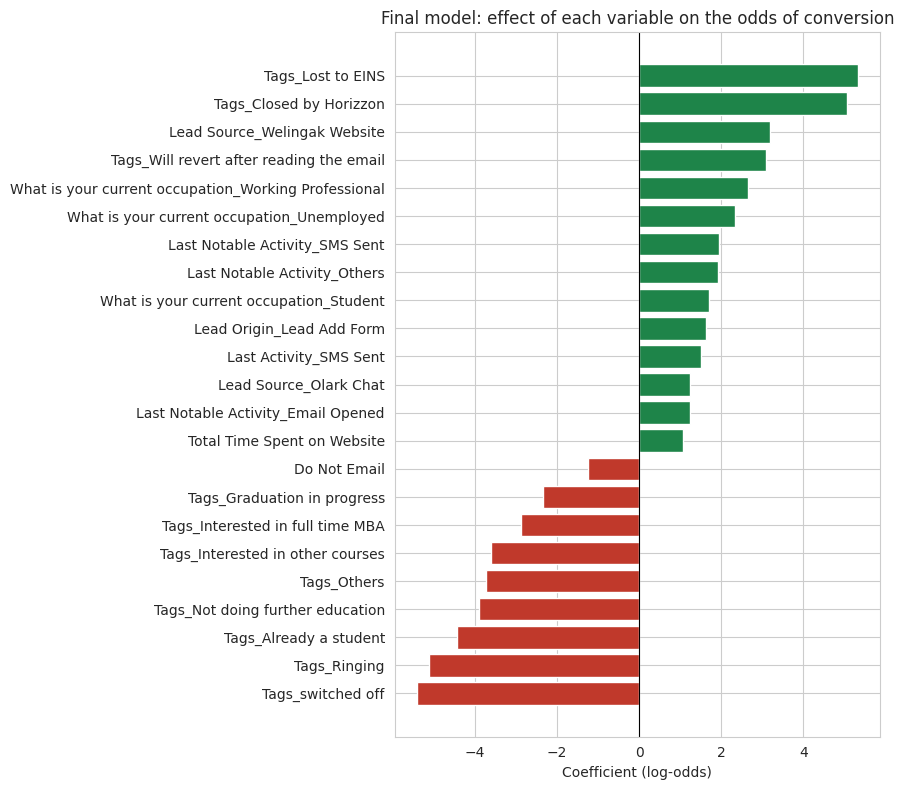

In [175]:
# coefficients as a picture (sorted) - green raises the chance of conversion, red lowers it
coefs = final_model['coef'].drop('const').sort_values()
plt.figure(figsize=(9, 8))
plt.barh(coefs.index, coefs.values, color=['#1e8449' if v > 0 else '#c0392b' for v in coefs.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient (log-odds)')
plt.title('Final model: effect of each variable on the odds of conversion')
plt.tight_layout()
plt.show()

**How to read the model in simple words** (all comparisons are against a lead with the reference level, e.g. `Not Specified` or `Google`):
* **Time on website** – each extra standard deviation of time spent multiplies the odds of conversion by about 3 (coef 1.08).
* **Who they are** – working professionals (coef 2.7) and unemployed leads (2.3) are far more likely to convert than leads with no occupation given.
* **Where they came from** – `Welingak Website` (3.2) and `Lead Add Form` (1.6) push the odds up compared with Google. (`Olark Chat` also shows a positive sign here even though its raw conversion rate is low – once occupation and tags are held constant it is not worse than Google.)
* **Sales follow-up status (Tags)** – "Closed by Horizzon", "Lost to EINS" and "Will revert after reading the email" are strong positives; "Ringing", "switched off", "Already a student" are strong negatives.
* **Do Not Email = Yes** lowers the odds (coef –1.2, odds x0.29).

## 7. Model evaluation on the train set
### 7.1 Predictions at the default 0.5 cut-off

In [176]:
y_train_prob = predict_prob(X_train, final_model)
train_results = pd.DataFrame({'Converted': y_train, 'Conv_Prob': y_train_prob})
train_results['Predicted'] = (train_results['Conv_Prob'] > 0.5).astype(int)
train_results.head()

,Converted,Conv_Prob,Predicted
7356,1,0.974367,1
3109,0,0.000605,0
3845,1,0.991506,1
1020,1,0.923170,1
2903,0,0.000681,0


In [177]:
confusion = metrics.confusion_matrix(train_results['Converted'], train_results['Predicted'])
print(pd.DataFrame(confusion, index=['Actual 0', 'Actual 1'], columns=['Pred 0', 'Pred 1']))
print()
for name, value in evaluate(y_train, y_train_prob, 0.5).items():
    print(f'{name:12s}: {value:.3f}')

          Pred 0  Pred 1
Actual 0    3824     151
Actual 1     215    2278

Cutoff      : 0.500
Accuracy    : 0.943
Sensitivity : 0.914
Specificity : 0.962
Precision   : 0.938


### 7.2 ROC curve

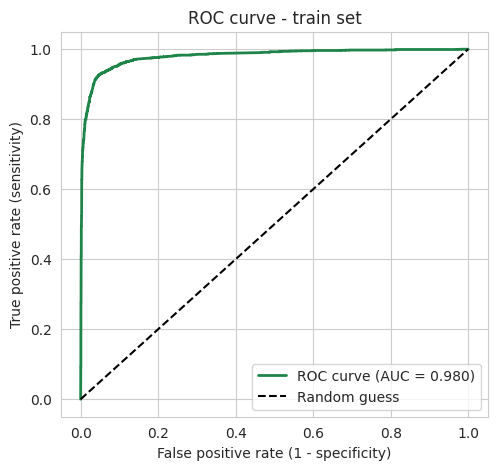

In [178]:
def plot_roc(y_true, prob, title):
    fpr, tpr, _ = metrics.roc_curve(y_true, prob)
    auc = metrics.roc_auc_score(y_true, prob)
    plt.figure(figsize=(5.5, 5))
    plt.plot(fpr, tpr, color='#1e8449', linewidth=2, label=f'ROC curve (AUC = {auc:.3f})')
    plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
    plt.xlabel('False positive rate (1 - specificity)')
    plt.ylabel('True positive rate (sensitivity)')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.show()
    return auc

train_auc = plot_roc(y_train, y_train_prob, 'ROC curve - train set')

An AUC of about 0.98 means the model ranks a converted lead above a non-converted one 98% of the time – an excellent separation.

### 7.3 Choosing the probability cut-off
0.5 was arbitrary. I look at how accuracy, sensitivity and specificity change with the cut-off, and also at the precision–recall trade-off, using the **train set only**.

In [179]:
cutoffs = np.round(np.arange(0.05, 1.0, 0.05), 2)
cutoff_table = pd.DataFrame([evaluate(y_train, y_train_prob, c) for c in cutoffs])
cutoff_table.round(3)

,Cutoff,Accuracy,Sensitivity,Specificity,Precision
0,0.05,0.832,0.983,0.737,0.701
1,0.10,0.882,0.974,0.825,0.777
2,0.15,0.914,0.963,0.884,0.838
3,0.20,0.920,0.958,0.897,0.853
4,0.25,0.924,0.951,0.907,0.865
5,0.30,0.934,0.940,0.930,0.894
6,0.35,0.939,0.933,0.944,0.912
7,0.40,0.942,0.927,0.952,0.924
8,0.45,0.944,0.920,0.958,0.933
9,0.50,0.943,0.914,0.962,0.938


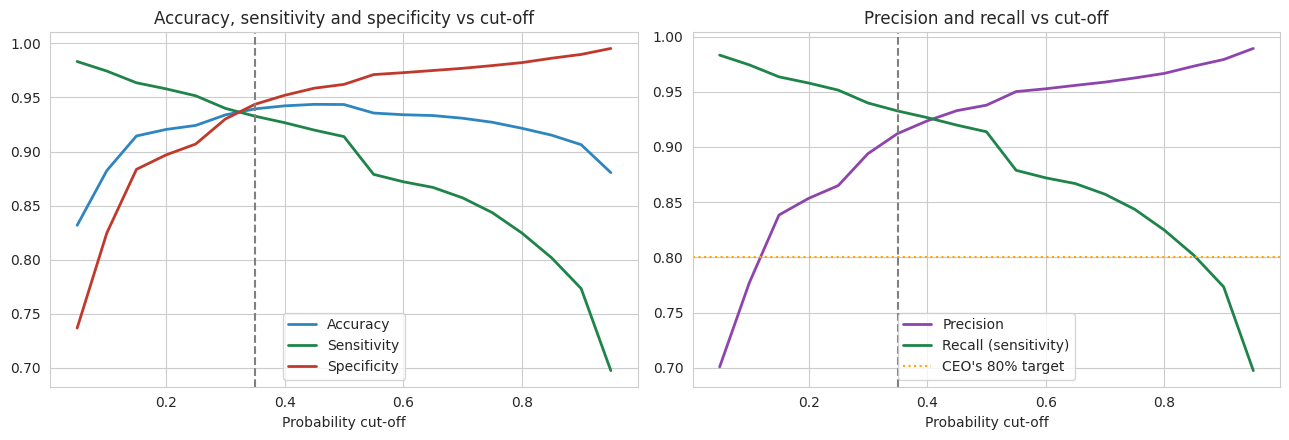

In [180]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# left: accuracy / sensitivity / specificity
for col, colour in zip(['Accuracy', 'Sensitivity', 'Specificity'], ['#2e86c1', '#1e8449', '#c0392b']):
    axes[0].plot(cutoff_table['Cutoff'], cutoff_table[col], label=col, color=colour, linewidth=2)
axes[0].axvline(0.35, color='grey', linestyle='--')
axes[0].set_title('Accuracy, sensitivity and specificity vs cut-off')
axes[0].set_xlabel('Probability cut-off')
axes[0].legend()

# right: precision vs recall (recall = sensitivity)
axes[1].plot(cutoff_table['Cutoff'], cutoff_table['Precision'], label='Precision', color='#8e44ad', linewidth=2)
axes[1].plot(cutoff_table['Cutoff'], cutoff_table['Sensitivity'], label='Recall (sensitivity)', color='#1e8449', linewidth=2)
axes[1].axhline(0.80, color='orange', linestyle=':', label="CEO's 80% target")
axes[1].axvline(0.35, color='grey', linestyle='--')
axes[1].set_title('Precision and recall vs cut-off')
axes[1].set_xlabel('Probability cut-off')
axes[1].legend()
plt.tight_layout()
plt.show()

* Accuracy, sensitivity and specificity all meet at about **0.30**.
* Precision and recall meet at about **0.40**.
* The business wants a high conversion rate among the leads it calls (precision, target 80%) but should not miss many buyers (sensitivity).

I choose **0.35**, in between the two crossing points: sensitivity is about 93% while precision is about 91%, well over the CEO's 80% target.

In [181]:
FINAL_CUTOFF = 0.35
train_metrics = evaluate(y_train, y_train_prob, FINAL_CUTOFF)
train_results['Predicted'] = (train_results['Conv_Prob'] > FINAL_CUTOFF).astype(int)
print(pd.DataFrame(metrics.confusion_matrix(y_train, train_results['Predicted']),
                   index=['Actual 0', 'Actual 1'], columns=['Pred 0', 'Pred 1']))
print()
for name, value in train_metrics.items():
    print(f'{name:12s}: {value:.3f}')

          Pred 0  Pred 1
Actual 0    3751     224
Actual 1     168    2325

Cutoff      : 0.350
Accuracy    : 0.939
Sensitivity : 0.933
Specificity : 0.944
Precision   : 0.912


## 8. Predictions on the test set
Same steps, but nothing is re-fitted: same variables, same coefficients, same scaler (already applied above), same cut-off.

          Pred 0  Pred 1
Actual 0    1600     104
Actual 1      76     992



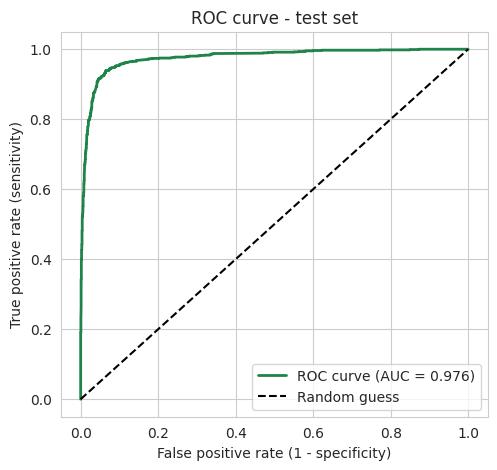

In [182]:
y_test_prob = predict_prob(X_test, final_model)
test_metrics = evaluate(y_test, y_test_prob, FINAL_CUTOFF)

print(pd.DataFrame(metrics.confusion_matrix(y_test, (y_test_prob > FINAL_CUTOFF).astype(int)),
                   index=['Actual 0', 'Actual 1'], columns=['Pred 0', 'Pred 1']))
print()
test_auc = plot_roc(y_test, y_test_prob, 'ROC curve - test set')

In [183]:
# train vs test side by side - a big gap would mean over-fitting
comparison = pd.DataFrame({'Train': train_metrics, 'Test': test_metrics}).drop('Cutoff')
comparison.loc['AUC'] = [train_auc, test_auc]
comparison.round(3)

,Train,Test
Accuracy,0.939,0.935
Sensitivity,0.933,0.929
Specificity,0.944,0.939
Precision,0.912,0.905
AUC,0.980,0.976


Train and test are within about one percentage point of each other on every metric, so the model **generalises well** and is not over-fitted. At the chosen cut-off it correctly identifies ~93% of the leads that convert, and ~91% of the leads it calls hot actually convert.

## 9. Lead score for every lead
**Lead Score = predicted probability of conversion × 100.** A lead is *hot* if its score is above 35 (the cut-off).

In [184]:
# probabilities for all 9,240 leads (train + test), attached to the original IDs
X_all = pd.concat([X_train, X_test]).sort_index()
lead_scores = lead_ids.copy()
lead_scores['Converted'] = y.loc[X_all.index]
lead_scores['Lead Score'] = (predict_prob(X_all, final_model) * 100).round(0).astype(int)
lead_scores['Lead Type'] = np.where(lead_scores['Lead Score'] > FINAL_CUTOFF * 100, 'Hot', 'Cold')

lead_scores.sort_values('Lead Score', ascending=False).head(10)

,Prospect ID,Lead Number,Converted,Lead Score,Lead Type
4909,4cd96674-37c4-4538-9fd4-f9a172b82b08,612869,1,100,Hot
4927,6da7eb54-08b7-4c67-8a16-bbcb00acd84c,612731,1,100,Hot
4926,195b618f-d944-4da2-8eeb-d21842f0c74e,612736,1,100,Hot
4947,bd5ca024-ab3a-4292-8be4-b9a4c3200e86,612578,1,100,Hot
4902,681f609a-e7fb-42b0-a779-431582455c98,612954,1,100,Hot
4900,fcc49ba4-589a-4166-b66f-7f2dfb9d1e71,612971,1,100,Hot
4896,b50b45b2-c22a-4821-b0ef-b9113cee5a59,613016,1,100,Hot
4892,397aede3-7ce8-40c9-808c-b290df2af480,613042,1,100,Hot
4860,729e244b-5298-4cec-b31d-ac620bd1af81,613438,1,100,Hot
4858,e2ad0787-4347-4e35-9dca-62ee420ed770,613459,1,100,Hot


In [185]:
hot = lead_scores[lead_scores['Lead Type'] == 'Hot']
print('Hot leads          :', len(hot), f'({len(hot) / len(lead_scores) * 100:.0f}% of all leads)')
print('Conversion - all   :', round(lead_scores['Converted'].mean() * 100, 1), '%')
print('Conversion - hot   :', round(hot['Converted'].mean() * 100, 1), '%   (CEO target: 80%)')
print('Conversion - cold  :', round(lead_scores.loc[lead_scores["Lead Type"] == "Cold", "Converted"].mean() * 100, 1), '%')

Hot leads          : 3633 (39% of all leads)
Conversion - all   : 38.5 %
Conversion - hot   : 91.2 %   (CEO target: 80%)
Conversion - cold  : 4.4 %


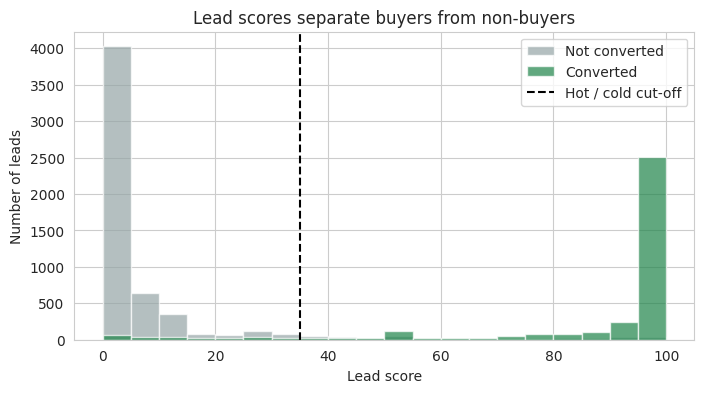

In [186]:
plt.figure(figsize=(8, 4))
plt.hist(lead_scores.loc[lead_scores['Converted'] == 0, 'Lead Score'], bins=20, alpha=0.7, color='#95a5a6', label='Not converted')
plt.hist(lead_scores.loc[lead_scores['Converted'] == 1, 'Lead Score'], bins=20, alpha=0.7, color='#1e8449', label='Converted')
plt.axvline(FINAL_CUTOFF * 100, color='black', linestyle='--', label='Hot / cold cut-off')
plt.xlabel('Lead score')
plt.ylabel('Number of leads')
plt.title('Lead scores separate buyers from non-buyers')
plt.legend()
plt.show()

### Decile / gains analysis (business view)
If the sales team calls leads from the highest score downward, how much of the total conversions do they capture?

In [187]:
lead_scores['Decile'] = pd.qcut(lead_scores['Lead Score'].rank(method='first', ascending=False), 10, labels=range(1, 11)).astype(int)
gains = lead_scores.groupby('Decile')['Converted'].agg(['count', 'sum', 'mean']).rename(columns={'count': 'Leads', 'sum': 'Conversions', 'mean': 'Conv rate'})
gains['Cum % of conversions'] = gains['Conversions'].cumsum() / gains['Conversions'].sum() * 100
gains['Lift'] = gains['Conv rate'] / lead_scores['Converted'].mean()
gains.round(2)

,Leads,Conversions,Conv rate,Cum % of conversions,Lift
Decile,,,,,
1,924,918,0.99,25.78,2.58
2,924,915,0.99,51.47,2.57
3,924,876,0.95,76.07,2.46
4,924,626,0.68,93.65,1.76
5,924,143,0.15,97.67,0.40
6,924,41,0.04,98.82,0.12
7,924,17,0.02,99.30,0.05
8,924,12,0.01,99.63,0.03
9,924,8,0.01,99.86,0.02


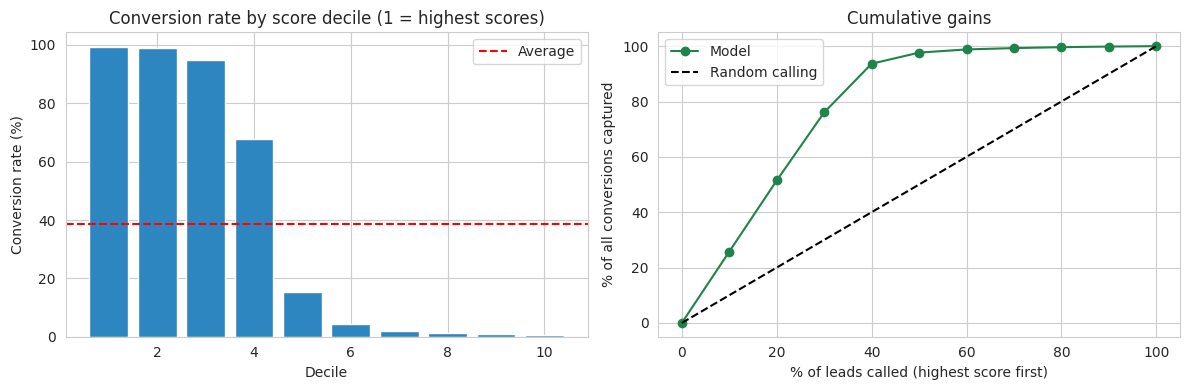

In [188]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(gains.index, gains['Conv rate'] * 100, color='#2e86c1')
axes[0].axhline(lead_scores['Converted'].mean() * 100, color='red', linestyle='--', label='Average')
axes[0].set_title('Conversion rate by score decile (1 = highest scores)')
axes[0].set_xlabel('Decile')
axes[0].set_ylabel('Conversion rate (%)')
axes[0].legend()

axes[1].plot([0] + list(gains.index * 10), [0] + list(gains['Cum % of conversions']), marker='o', color='#1e8449', label='Model')
axes[1].plot([0, 100], [0, 100], 'k--', label='Random calling')
axes[1].set_title('Cumulative gains')
axes[1].set_xlabel('% of leads called (highest score first)')
axes[1].set_ylabel('% of all conversions captured')
axes[1].legend()
plt.tight_layout()
plt.show()

The top 3 deciles (30% of the leads) contain about 76% of all conversions, and the top 4 deciles contain about 94%. Calling in score order gives the sales team roughly **2.5x the yield per call** compared with calling at random (lift of 2.5 in the top three deciles).

## 10. Trying other models
One model is not enough evidence that the choice is right. I compare the final logistic regression with:
1. logistic regression using **all** 70 variables (no selection),
2. logistic regression with a smaller RFE-15 set,
3. logistic regression **without the `Tags` variables** (what we can do when scoring a brand-new lead, before any sales call),
4. a decision tree and 5. a random forest, both tuned with grid search.

All models are compared on the **test set at the same 0.35 cut-off**, plus AUC, which does not depend on a cut-off.

In [189]:
def select_features(X, y, n_rfe, p_limit=0.05, vif_limit=5):
    """RFE first cut, then remove the highest p-value (or VIF) one at a time - the same process I did by hand above."""
    rfe_model = RFE(LogisticRegression(max_iter=1000), n_features_to_select=n_rfe).fit(X, y)
    cols = X.columns[rfe_model.support_].tolist()
    while True:
        table = fit_logit(X[cols], y)
        p_values = table['P>|z|'].drop('const')
        vifs = vif_table(X[cols])
        if p_values.max() > p_limit:
            cols.remove(p_values.idxmax())
        elif vifs.iloc[0] > vif_limit:
            cols.remove(vifs.index[0])
        else:
            return cols, table


model_scores = []          # one row per model
test_probs = {}            # kept for the ROC comparison

def record(name, n_vars, prob):
    row = evaluate(y_test, prob, FINAL_CUTOFF)
    model_scores.append({'Model': name, 'Variables': n_vars, 'AUC': metrics.roc_auc_score(y_test, prob),
                         'Accuracy': row['Accuracy'], 'Sensitivity': row['Sensitivity'],
                         'Specificity': row['Specificity'], 'Precision': row['Precision']})
    test_probs[name] = prob

In [190]:
# 1) logistic regression with every variable
lr_all = LogisticRegression(max_iter=2000).fit(X_train, y_train)
record('LR - all variables', X_train.shape[1], pd.Series(lr_all.predict_proba(X_test)[:, 1], index=X_test.index))

# 2) smaller RFE set (15)
cols_15, table_15 = select_features(X_train, y_train, 15)
record('LR - RFE 15', len(cols_15), predict_prob(X_test, table_15))

# 3) FINAL model (RFE 25 + p-value + VIF)
record('LR - FINAL (RFE 25)', len(final_cols), y_test_prob)

In [191]:
# 4) without any Tags variables - 'cold start' model for brand-new leads
no_tag_cols = [c for c in X_train.columns if not c.startswith('Tags_')]
cols_nt, table_nt = select_features(X_train[no_tag_cols], y_train, 20)
record('LR - without Tags', len(cols_nt), predict_prob(X_test, table_nt))
print('Variables kept without Tags:', len(cols_nt))

Variables kept without Tags: 20


In [192]:
# 5) decision tree - tune depth and leaf size with 5-fold CV
tree_grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                         {'max_depth': [4, 6, 8, 10], 'min_samples_leaf': [10, 30, 60]},
                         cv=5, scoring='roc_auc').fit(X_train, y_train)
print('Best tree parameters:', tree_grid.best_params_, '| CV AUC:', round(tree_grid.best_score_, 4))
record('Decision tree', X_train.shape[1], pd.Series(tree_grid.predict_proba(X_test)[:, 1], index=X_test.index))

Best tree parameters: {'max_depth': 10, 'min_samples_leaf': 30} | CV AUC: 0.9663


In [193]:
# 6) random forest - small grid to keep the run time short
rf_grid = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
                       {'max_depth': [6, 10], 'min_samples_leaf': [5, 20]},
                       cv=3, scoring='roc_auc').fit(X_train, y_train)
print('Best forest parameters:', rf_grid.best_params_, '| CV AUC:', round(rf_grid.best_score_, 4))
record('Random forest', X_train.shape[1], pd.Series(rf_grid.predict_proba(X_test)[:, 1], index=X_test.index))

Best forest parameters: {'max_depth': 10, 'min_samples_leaf': 5} | CV AUC: 0.9724


In [194]:
model_table = pd.DataFrame(model_scores).set_index('Model')
model_table.round(3)

,Variables,AUC,Accuracy,Sensitivity,Specificity,Precision
Model,,,,,,
LR - all variables,70,0.976,0.937,0.929,0.942,0.910
LR - RFE 15,15,0.962,0.922,0.926,0.920,0.878
LR - FINAL (RFE 25),23,0.976,0.935,0.929,0.939,0.905
LR - without Tags,20,0.884,0.805,0.825,0.792,0.713
Decision tree,70,0.965,0.922,0.895,0.940,0.903
Random forest,70,0.971,0.911,0.928,0.901,0.854


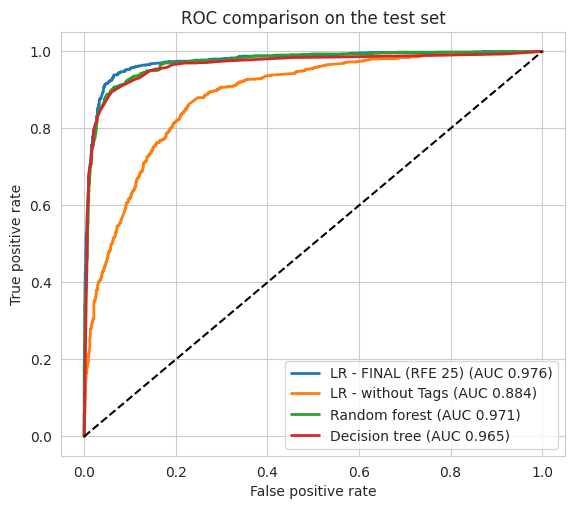

In [195]:
# ROC curves of the main models on the test set
plt.figure(figsize=(6.5, 5.5))
for name in ['LR - FINAL (RFE 25)', 'LR - without Tags', 'Random forest', 'Decision tree']:
    fpr, tpr, _ = metrics.roc_curve(y_test, test_probs[name])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC {metrics.roc_auc_score(y_test, test_probs[name]):.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC comparison on the test set')
plt.legend(loc='lower right')
plt.show()

**Reading the comparison**
* The final logistic regression matches the 70-variable model (AUC 0.976 for both, accuracy 93.5% vs 93.7%) and beats the random forest (AUC 0.971) and the decision tree (0.965). It does that with 23 variables and it is the only one that is easy to explain, so there is no reason to give up interpretability.
* The smaller RFE-15 model is clearly weaker (AUC 0.962), which supports the choice of 25 in the cross-validation step.
* **Without `Tags` the accuracy falls to about 80% and AUC to 0.88.** So most of the model's power comes from what the sales team learns while talking to the lead. That is the honest limit of the model: it is a strong *nurturing-stage* scorer, and a weaker (but still useful, AUC 0.88) scorer for a lead nobody has contacted yet.

## 11. Answers to the business questions
### Q1. Top three variables that contribute most to the probability of conversion
I rank the variables by their coefficient (log-odds) in the final model.

In [196]:
coef_table = final_model.drop('const')[['coef', 'Odds ratio']].sort_values('coef', ascending=False)
coef_table.head(6).round(2)

,coef,Odds ratio
Tags_Lost to EINS,5.32,205.22
Tags_Closed by Horizzon,5.07,158.46
Lead Source_Welingak Website,3.18,23.97
Tags_Will revert after reading the email,3.08,21.73
What is your current occupation_Working Professional,2.66,14.28
What is your current occupation_Unemployed,2.34,10.35


The three biggest positive drivers are **`Tags_Lost to EINS`** (+5.32), **`Tags_Closed by Horizzon`** (+5.07) and **`Lead Source_Welingak Website`** (+3.18). The first two are statuses the sales team records once a lead has already made a decision, so they confirm the outcome rather than cause it. The most important *behavioural* variable is **`Total Time Spent on Website`** (+1.08 per standard deviation – odds almost triple).

### Q2. Top three categorical (dummy) variables the company should focus on
Tags are sales-recorded outcomes, so I leave them out here and look at the dummies the company can actually influence.

In [197]:
lever_cols = [c for c in coef_table.index if not c.startswith('Tags_') and c not in num_cols and coef_table.loc[c, 'coef'] > 0]
coef_table.loc[lever_cols].round(2)

,coef,Odds ratio
Lead Source_Welingak Website,3.18,23.97
What is your current occupation_Working Professional,2.66,14.28
What is your current occupation_Unemployed,2.34,10.35
Last Notable Activity_SMS Sent,1.95,7.02
Last Notable Activity_Others,1.93,6.90
What is your current occupation_Student,1.70,5.48
Lead Origin_Lead Add Form,1.63,5.08
Last Activity_SMS Sent,1.51,4.54
Lead Source_Olark Chat,1.23,3.43
Last Notable Activity_Email Opened,1.23,3.43


Focus on: **(1) `Lead Source_Welingak Website`** (odds x24), **(2) `Occupation_Working Professional`** (odds x14) and **(3) `Lead Origin_Lead Add Form`** (odds x5). `Last Activity_SMS Sent` (x4.5) is the next best and is fully in the sales team's control. (`Unemployed` also has a large coefficient, but that is mainly the contrast with leads who left occupation blank; it is the biggest group already and not a segment to "go after".)

### Q3 and Q4. Adjusting the cut-off to the business situation
The lead score can be turned into a different calling policy just by moving the cut-off. I check three policies on the **test set** and compare with calling everybody.

In [198]:
def call_plan(y_true, prob, cutoff):
    """What happens if the team calls every lead whose probability is above the cut-off?"""
    called = prob > cutoff
    return {'Leads called': int(called.sum()),
            '% of leads called': called.mean() * 100,
            'Conversion rate of calls (precision)': y_true[called].mean() * 100,
            '% of all buyers reached': y_true[called].sum() / y_true.sum() * 100,
            'Useless calls (non-buyers)': int((y_true[called] == 0).sum()),
            'Buyers missed': int(y_true[~called].sum())}

plans = {'Call everyone (no model)': -1,
         'Intern season (cut-off 0.15)': 0.15,
         'Normal (cut-off 0.35)': 0.35,
         'Target reached (cut-off 0.80)': 0.80}
strategy = pd.DataFrame({name: call_plan(y_test, y_test_prob, c) for name, c in plans.items()}).T
strategy.round(1)

,Leads called,% of leads called,Conversion rate of calls (precision),% of all buyers reached,Useless calls (non-buyers),Buyers missed
Call everyone (no model),2772.0,100.0,38.5,100.0,1704.0,0.0
Intern season (cut-off 0.15),1219.0,44.0,84.2,96.1,193.0,42.0
Normal (cut-off 0.35),1096.0,39.5,90.5,92.9,104.0,76.0
Target reached (cut-off 0.80),922.0,33.3,95.1,82.1,45.0,191.0


In [199]:
# score bands - a simple way to hand out work
bands = pd.cut(y_test_prob * 100, [-1, 15, 35, 80, 100], labels=['0-15 (cold)', '16-35 (lukewarm)', '36-80 (warm)', '81-100 (hot)'])
band_table = y_test.groupby(bands).agg(['count', 'mean'])
band_table.columns = ['Leads', 'Conversion rate']
band_table['Conversion rate'] = (band_table['Conversion rate'] * 100).round(1)
band_table

,Leads,Conversion rate
0-15 (cold),1553,2.7
16-35 (lukewarm),123,27.6
36-80 (warm),174,66.1
81-100 (hot),922,95.1


**Q3 – intern season (aggressive: reach almost every potential buyer).**
Lower the cut-off to about **0.15** (score 15). On the test set the team then calls 1,219 leads instead of 1,096 (123 extra calls, all of them for interns), reaches **96.1% of all buyers** (vs 92.9%), and the conversion rate of calls is still **84%, above the CEO's 80% target**. Going lower than 0.15 pushes the rate below 80%, so 0.15 is the natural floor. The interns take the lukewarm (score 16–35) and warm (36–80) leads, while the experienced reps stay on the 81–100 leads.

**Q4 – target already met (minimise useless calls).**
Raise the cut-off to about **0.80** (score 80). Only 33% of the leads are called, **95% of those calls convert**, and useless calls fall from 104 to 45 on the test set (a 57% cut). The price is that about 18% of buyers are not phoned – acceptable when the quarter's target is already met. Those leads (score 35–80) get automatic e-mail/SMS nurturing instead of phone calls, and are picked up again in the next cycle.

## 12. Conclusion and lessons learnt
* A 23-variable logistic regression scores leads with **AUC 0.976, accuracy 93.5% and sensitivity 92.9% on unseen data**. The leads it labels hot convert at **~91%** against a 38.5% base rate and the CEO's 80% target.
* Working in score order, the top 30% of leads hold ~76% of all conversions.
* Biggest lessons: (1) `Select` is a null value in disguise, (2) "missing" can carry information, so I kept it as its own level instead of filling with the mode, (3) always keep the scaler and the cut-off decision on the training data only, (4) a very strong feature such as `Tags` needs a conversation about *when* it is available – I therefore also report the no-Tags model.
* Next steps: monitor the model monthly, re-train when the hot-lead conversion rate drifts below 80%, and make sales tagging consistent and timely because it is the model's main fuel.